Modelli

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
import json
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from xgboost import XGBRegressor



In [2]:

from pathlib import Path

# Individua automaticamente la cartella del progetto
current_dir = Path.cwd().resolve()

BASE_DIR = next(
    (p for p in (current_dir, *current_dir.parents)
     if (p / "Dati").is_dir() and (p / "03_DashBoard").is_dir()),
    None
)

if BASE_DIR is None:
    raise FileNotFoundError("Cartella principale del progetto non trovata")

DATA_DIR = BASE_DIR / "Dati"
DASHBOARD_DIR = BASE_DIR / "03_DashBoard"
MODEL_DIR = DASHBOARD_DIR / "modello_r_f"


In [3]:
#Creiamo un file_path per semplificare l'accesso al dataframe appena creato in 01_FeatureSelection

file_path = DATA_DIR / "DataFrame_01.csv"

In [4]:
#Importiamo il dataframe appena creato in 01_FeatureSelection

df = pd.read_csv(file_path)

In [5]:
#Creiamo i due dataset: 1 con solo la variabile target e una con tutte le variabili e in seguito dividiamo i vari dataset in train e test con un rapporto 70 - 30 

X = df.drop(columns='adr')
y = df['adr']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=66)

In [6]:
#Dividiamo le variabili in numeriche e categoriche e prepariamo le variabili per essere processate dai modelli

variabili_numeriche = X_train.select_dtypes(include=np.number).columns.tolist()
variabili_categoriche = X_train.select_dtypes(exclude=np.number).columns.tolist()
 
pipeline_numeriche = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
 
pipeline_categoriche = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])
 
preprocessing = ColumnTransformer([
    ("numeriche", pipeline_numeriche, variabili_numeriche),
    ("categoriche", pipeline_categoriche, variabili_categoriche)
])

In [7]:
#Qui creiamo il nostro primo modello che verrà preso come punto di riferimento

modello_dummy = Pipeline([
    ("preprocessing", preprocessing),
    ("modello", DummyRegressor(strategy="median"))
]) 
modello_dummy.fit(X_train, y_train) 
predizioni_dummy = modello_dummy.predict(X_test)
 
print("MAPE:", round(mean_absolute_percentage_error(y_test, predizioni_dummy),3)*100, '%')
print('MAE:', round(mean_absolute_error(y_test, predizioni_dummy), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predizioni_dummy)), 3))
print("R²:", round(r2_score(y_test, predizioni_dummy), 3))


MAPE: 35.6 %
MAE: 34.099
RMSE: 46.76
R²: -0.041


In [8]:
#Qui utilizziamo il modello di regressione

modello_lineare = Pipeline([
    ("preprocessing", preprocessing),
    ("modello", LinearRegression())
])
modello_lineare.fit(X_train, y_train)
predizioni_lineare = modello_lineare.predict(X_test)
 
print("MAPE:", round(mean_absolute_percentage_error(y_test, predizioni_lineare),2)*100, '%')
print('MAE:', round(mean_absolute_error(y_test, predizioni_lineare), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predizioni_lineare)), 3))
print("R²:", round(r2_score(y_test, predizioni_lineare), 4))

MAPE: 23.0 %
MAE: 21.567
RMSE: 28.929
R²: 0.6016


In [9]:
#Qui utilizziamo il modelle ridge

modello_ridge = Pipeline([
    ("preprocessing", preprocessing),
    ("modello", Ridge(alpha=1.0))
]) 
modello_ridge.fit(X_train, y_train)
predizioni_ridge = modello_ridge.predict(X_test)

print("MAPE:", round(mean_absolute_percentage_error(y_test, predizioni_ridge),2)*100, '%')
print('MAE:', round(mean_absolute_error(y_test, predizioni_ridge), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predizioni_ridge)), 3))
print("R²:", round(r2_score(y_test, predizioni_ridge), 4))

MAPE: 23.0 %
MAE: 21.567
RMSE: 28.929
R²: 0.6016


In [10]:
#Qui utilizziamo il modello ad albero

modello_albero = Pipeline([
    ("preprocessing", preprocessing),
    ("modello", DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=10,
        random_state=42
    ))
])
modello_albero.fit(X_train, y_train)
predizioni_albero = modello_albero.predict(X_test)

print("MAPE:", round(mean_absolute_percentage_error(y_test, predizioni_albero),3)*100, '%')
print('MAE:', round(mean_absolute_error(y_test, predizioni_albero), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predizioni_albero)), 3))
print("R²:", round(r2_score(y_test, predizioni_albero), 3))

MAPE: 13.900000000000002 %
MAE: 13.448
RMSE: 20.107
R²: 0.808


In [11]:
#Qui utilizziamo il modello Random Forest


modello_random_forest = Pipeline([
    ("preprocessing", preprocessing),
    ("modello", RandomForestRegressor(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])
modello_random_forest.fit(X_train, y_train)
predizioni_random_forest = modello_random_forest.predict(X_test)
 
print("MAPE:", round(mean_absolute_percentage_error(y_test, predizioni_random_forest), 2)*100, '%')
print('MAE:', round(mean_absolute_error(y_test, predizioni_random_forest), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predizioni_random_forest)), 3))
print("R²:", round(r2_score(y_test, predizioni_random_forest), 3))

MAPE: 8.0 %
MAE: 8.359
RMSE: 14.638
R²: 0.898


In [12]:
#Qui utilizziamo il modello xgboost

modello_xgboost = Pipeline([
    ("preprocessing", preprocessing),
    ("modello", XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])
modello_xgboost.fit(X_train, y_train)
predizioni_xgboost = modello_xgboost.predict(X_test)

print("MAPE:", round(mean_absolute_percentage_error(y_test, predizioni_xgboost), 3)*100, '%')
print('MAE:', round(mean_absolute_error(y_test, predizioni_xgboost), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predizioni_xgboost)), 3))
print("R²:", round(r2_score(y_test, predizioni_xgboost), 3))

MAPE: 11.200000000000001 %
MAE: 10.874
RMSE: 16.078
R²: 0.877


,Modello,MAPE %,MAE,RMSE,R2
4,Random Forest,8.353,8.359,14.638,0.898
5,XGBoost,11.195,10.874,16.078,0.877
3,Decision Tree,13.867,13.448,20.107,0.808
1,Ridge Regressor,22.994,21.567,28.929,0.602
2,Linear Regression,22.994,21.567,28.929,0.602
0,Dummy Regressor,35.566,34.099,46.760,-0.041


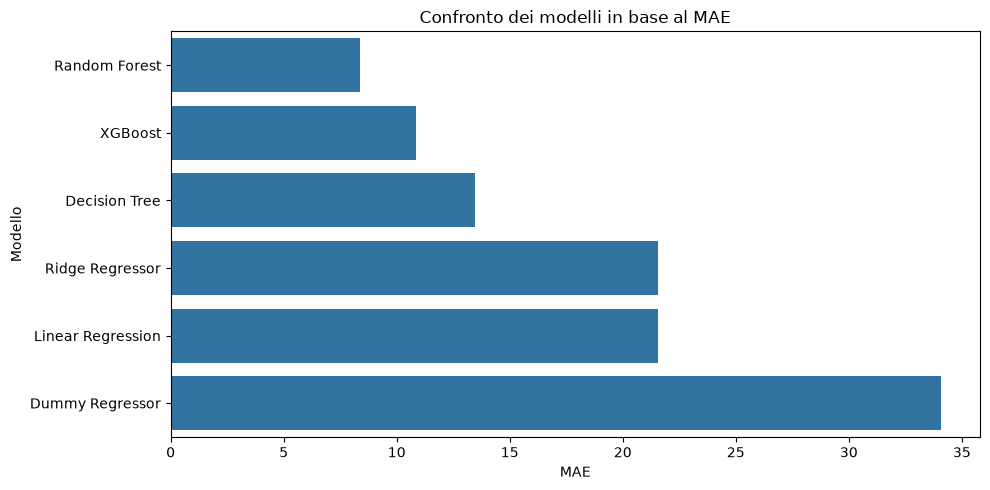

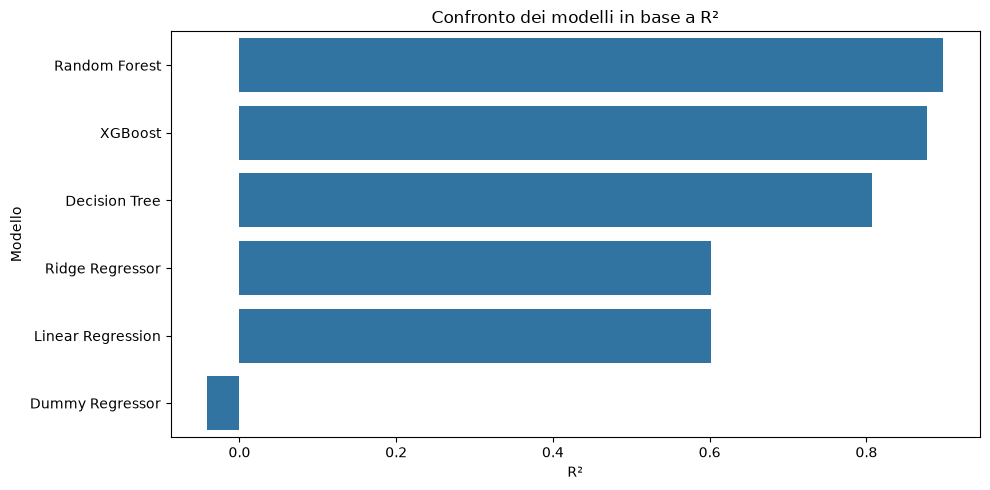

In [13]:
#Qui confrontiamo i modelli

modelli = {
    "Dummy Regressor": (modello_dummy, predizioni_dummy),
    "Ridge Regressor": (modello_ridge, predizioni_ridge),
    "Linear Regression": (modello_lineare, predizioni_lineare),
    "Decision Tree": (modello_albero, predizioni_albero),
    "Random Forest": (modello_random_forest, predizioni_random_forest),
    "XGBoost": (modello_xgboost, predizioni_xgboost)
}
 
risultati = []
 
for nome, (_, predizioni) in modelli.items():
    risultati.append({
        "Modello": nome,
        "MAPE %": mean_absolute_percentage_error(y_test, predizioni)*100,
        "MAE": mean_absolute_error(y_test, predizioni),
        "RMSE": np.sqrt(mean_squared_error(y_test, predizioni)),
        "R2": r2_score(y_test, predizioni)
    })
 
tabella_risultati = pd.DataFrame(risultati)
 
display(
    tabella_risultati
    .sort_values("MAE")
    .round(3)
) 

risultati_ordinati = tabella_risultati.sort_values("MAE")
 
plt.figure(figsize=(10, 5))
sns.barplot(data=risultati_ordinati, x="MAE", y="Modello")
plt.title("Confronto dei modelli in base al MAE")
plt.xlabel("MAE")
plt.ylabel("Modello")
plt.tight_layout()
plt.show() 
risultati_ordinati = tabella_risultati.sort_values("R2", ascending=False)
 
plt.figure(figsize=(10, 5))
sns.barplot(data=risultati_ordinati, x="R2", y="Modello")
plt.title("Confronto dei modelli in base a R²")
plt.xlabel("R²")
plt.ylabel("Modello")
plt.tight_layout()
plt.show()

Scegliamo il Random Forest in qunanto performa meglio

In [14]:
#Controllo sulla performance e overfitting

pred_train = modello_random_forest.predict(X_train)
 
print("R² train:", r2_score(y_train, pred_train))
print("R² test: ", r2_score(y_test, predizioni_random_forest))

R² train: 0.9469314308132611
R² test:  0.8980085975295681


In [15]:
#Qui facciamo un sample per confrontare i risultati del modello con i valori effettivi

y_pred = modello_random_forest.predict(X_test)

print("Predicted values:")
print(y_pred[:10])
 
print("\nActual values:")
print(y_test.iloc[:10].values)

joblib.dump(modello_random_forest, MODEL_DIR / "random_forest_model.joblib")
 
print("Modello salvato correttamente.") 

Predicted values:
[ 69.95969906 123.43072555  95.94018087  85.35690353  83.88200256
  50.32122025 121.53992153  62.18957135  73.97199586  89.20436101]

Actual values:
[ 50.   128.    89.1   85.    80.3   49.95 109.63  62.    68.    90.9 ]
Modello salvato correttamente.


In [16]:
# Serve per salvare le variabili e le metriche in formato json del modello random forest

with open(MODEL_DIR / "model_features.json", "w", encoding="utf-8") as file:
    json.dump(X_train.columns.tolist(), file, indent=4)

metrics = {k: v for k, v in risultati[4].items() if k != 'Modello'}
with open(MODEL_DIR / "model_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)
print("Modello e metriche sono state salvate")

Modello e metriche sono state salvate
